# NIDS — CTU-13 Final Training & Ablation

Sử dụng gói NIDS_Kaggle_Training commit dfb8446 và T01 đã chọn bằng validation. Cố định width=32, LR=0.001, dropout=0.1, không class weighting; 50 epoch tối đa, patience 10, batch 512, seed 42/43/44. Bốn baseline chạy seed 42; KNN giới hạn khoảng 20.000 mẫu train. Không chọn seed hoặc mô hình theo test. Gaussian độc lập, chọn ngưỡng trên validation với FPR mục tiêu 1%. Đây là đánh giá nội bộ, không phải kiểm thử độc lập theo kịch bản.

In [17]:
import sys
import torch
import numpy as np
import pandas as pd
import sklearn
import pyarrow
import xgboost
import lightgbm

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyArrow:", pyarrow.__version__)
print("XGBoost:", xgboost.__version__)
print("LightGBM:", lightgbm.__version__)

print("\nCUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("GPU count:", torch.cuda.device_count())

assert torch.cuda.is_available(), "GPU is not enabled"

for i in range(torch.cuda.device_count()):
    gpu = torch.cuda.get_device_properties(i)
    print(f"\nGPU {i}: {gpu.name}")
    print("VRAM GiB:", round(gpu.total_memory / 1024**3, 2))

print("\nGPU ENVIRONMENT READY")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
NumPy: 2.1.3
Pandas: 2.3.3
Scikit-learn: 1.6.1
PyArrow: 23.0.1
XGBoost: 3.4.1
LightGBM: 4.6.0

CUDA available: True
CUDA version: 13.0
GPU count: 2

GPU 0: Tesla T4
VRAM GiB: 14.56

GPU 1: Tesla T4
VRAM GiB: 14.56

GPU ENVIRONMENT READY


In [18]:
from pathlib import Path
from zipfile import ZipFile
import shutil
import os

INPUT = Path("/kaggle/input")
ROOT = Path("/kaggle/working/NIDS")

ROOT.mkdir(parents=True, exist_ok=True)

manifests = list(INPUT.rglob("kaggle_manifest.json"))

if manifests:

    source = manifests[0].parent

    print("Dataset source:", source)

    shutil.copytree(
        source,
        ROOT,
        dirs_exist_ok=True
    )

else:

    archives = list(
        INPUT.rglob("NIDS_Kaggle_Training.zip")
    )

    assert archives, "Training package not found"

    with ZipFile(archives[0]) as z:
        z.extractall(ROOT)

os.chdir(ROOT)

os.environ["PYTHONPATH"] = str(ROOT / "src")

assert (ROOT / "src/nids/final_cnn.py").exists()
assert (ROOT / "kaggle_manifest.json").exists()

print("Project root:", Path.cwd())

print("\nKAGGLE PROJECT READY")

Dataset source: /kaggle/input/datasets/chienvoo/nids-kaggle-training
Project root: /kaggle/working/NIDS

KAGGLE PROJECT READY


In [19]:
import hashlib
import json

manifest = json.loads(
    (ROOT / "kaggle_manifest.json").read_text(
        encoding="utf-8"
    )
)

print("Git commit:", manifest["git_commit"])

for relative, expected in manifest["sha256"].items():

    path = ROOT / relative

    assert path.exists(), f"Missing file: {relative}"

    h = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(1048576), b""
        ):
            h.update(block)

    assert h.hexdigest() == expected, relative

    print("PASS:", relative)

print("\nKAGGLE DATA INTEGRITY PASSED")

Git commit: dfb84460072a0bcaeed01d9eec0e1ac0dd371531
PASS: data/processed/final/cic/train.parquet
PASS: data/processed/final/cic/validation.parquet
PASS: data/processed/final/cic/test.parquet
PASS: data/processed/final/cic/manifest.json
PASS: data/processed/final/cic/split_indices.npz
PASS: data/processed/final/ctu/train.parquet
PASS: data/processed/final/ctu/validation.parquet
PASS: data/processed/final/ctu/test.parquet
PASS: data/processed/final/ctu/manifest.json
PASS: data/processed/final/ctu/split_indices.npz

KAGGLE DATA INTEGRITY PASSED


In [20]:
subprocess_check = __import__("subprocess")
subprocess_check.run([sys.executable, "-m", "nids.final_cnn", "--help"], cwd=ROOT, check=True)

usage: final_cnn.py [-h] [--dataset {cic,ctu,both}]
                    [--variants {cnn,cnn_se,cnn_mhsa,cnn_se_mhsa} [{cnn,cnn_se,cnn_mhsa,cnn_se_mhsa} ...]]
                    [--smoke] [--epochs EPOCHS] [--batch-size BATCH_SIZE]
                    [--width WIDTH] [--lr LR] [--dropout DROPOUT]
                    [--patience PATIENCE] [--seed SEED]
                    [--device {auto,cpu,cuda}]
                    [--class-weight {auto,none,sqrt,balanced}] [--amp]
                    [--tune-only] [--run-id RUN_ID]

options:
  -h, --help            show this help message and exit
  --dataset {cic,ctu,both}
  --variants {cnn,cnn_se,cnn_mhsa,cnn_se_mhsa} [{cnn,cnn_se,cnn_mhsa,cnn_se_mhsa} ...]
  --smoke
  --epochs EPOCHS
  --batch-size BATCH_SIZE
  --width WIDTH
  --lr LR
  --dropout DROPOUT
  --patience PATIENCE
  --seed SEED
  --device {auto,cpu,cuda}
  --class-weight {auto,none,sqrt,balanced}
  --amp
  --tune-only
  --run-id RUN_ID


CompletedProcess(args=['/usr/bin/python3', '-m', 'nids.final_cnn', '--help'], returncode=0)

In [21]:
subprocess_check.run([sys.executable, "-m", "pytest", "-q", "tests/test_final_pipeline.py", "tests/test_final_cnn.py", "tests/test_final_tuning.py"], cwd=ROOT, check=True)

.................                                                        [100%]
=============================== warnings summary ===============================
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64
  /usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
    prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))

../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
../../../usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85
  /usr/local/l

CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', '-q', 'tests/test_final_pipeline.py', 'tests/test_final_cnn.py', 'tests/test_final_tuning.py'], returncode=0)

## 2. Cố định thiết kế và kiểm tra dữ liệu

In [22]:
import subprocess, sys, os, json, shutil, hashlib
import pandas as pd
import numpy as np
from pathlib import Path
assert manifest['git_commit'].startswith('dfb8446')
DATA = ROOT/'data/processed/final/ctu'
meta = json.loads((DATA/'manifest.json').read_text())
SIZES = {'train':57903,'validation':12408,'test':12408}
assert meta['split_sizes'] == SIZES
VARIANTS = ['cnn','cnn_se','cnn_mhsa','cnn_se_mhsa']
SEEDS = [42,43,44]
OUT = ROOT/'outputs/final/full/ctu'
RUNS = ROOT/'outputs/final/ctu_final_runs'
REPORT = ROOT/'reports/final/ctu_final'
RUNS.mkdir(parents=True,exist_ok=True)
REPORT.mkdir(parents=True,exist_ok=True)
ENV = {**os.environ,'PYTHONPATH':str(ROOT/'src')}
PLAN = dict(width=32,lr=.001,dropout=.1,class_weight='none',epochs=50,patience=10,batch_size=512,seeds=SEEDS,variants=VARIANTS,commit=manifest['git_commit'])
p = RUNS/'plan.json'
if p.exists(): assert json.loads(p.read_text()) == PLAN
else: p.write_text(json.dumps(PLAN,indent=2))
print('DESIGN LOCKED',PLAN)
def run(module, args):
    subprocess.run([sys.executable,'-u','-m',module,*args],cwd=ROOT,env=ENV,check=True)
def check_common(d):
    assert d['dataset']=='ctu' and d['profile']=='full'
    assert d['split_sizes']==SIZES and d['split_sha256']==meta['split_sha256']
    assert d['classes']==['0','1'] and d['features']==meta['features']


DESIGN LOCKED {'width': 32, 'lr': 0.001, 'dropout': 0.1, 'class_weight': 'none', 'epochs': 50, 'patience': 10, 'batch_size': 512, 'seeds': [42, 43, 44], 'variants': ['cnn', 'cnn_se', 'cnn_mhsa', 'cnn_se_mhsa'], 'commit': 'dfb84460072a0bcaeed01d9eec0e1ac0dd371531'}


## 3. Bốn ML baseline — cùng tập validation/test
Chạy CPU; KNN dùng tập prototype giới hạn theo mã nguồn. Gaussian mặc định của module chỉ lưu làm đối chứng; phần sau tối ưu độc lập.

In [23]:
base = RUNS/'baseline'
if not base.exists():
    if OUT.exists() and any(OUT.iterdir()):
        raise RuntimeError('Archive existing full/ctu output before starting baseline')
    run('nids.final_baselines',['--dataset','ctu'])
    d=json.loads((OUT/'baseline_metrics.json').read_text()); check_common(d)
    assert set(d['models'])=={'Random Forest','XGBoost','LightGBM','KNN'}
    shutil.move(str(OUT),str(base))
baseline=json.loads((base/'baseline_metrics.json').read_text()); check_common(baseline)
assert set(baseline['models'])=={'Random Forest','XGBoost','LightGBM','KNN'}
display(pd.read_csv(base/'baseline_metrics.csv'))



=== CTU / full ===
Train: 57903
Validation: 12408
Test: 12408
Classes: ['0', '1']
Training: Random Forest
Random Forest F1-score: 0.996206
Training: XGBoost
XGBoost F1-score: 0.99718
Training: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

LightGBM F1-score: 0.99783
Training: KNN
KNN F1-score: 0.986319

BASELINE RESULTS
        Model  Accuracy  Precision   Recall  F1-score      FPR  Validation F1  Training rows  Training seconds
Random Forest  0.997179   0.996098 0.996314  0.996206 0.002309       0.996529          57903          7.577709
      XGBoost  0.997905   0.997613 0.996748  0.997180 0.001411       0.996637          57903          2.092750
     LightGBM  0.998388   0.998480 0.997181  0.997830 0.000898       0.997395          57903          1.886197
          KNN  0.989845   0.987821 0.984822  0.986319 0.007183       0.985337          20000          0.001814

GAUSSIAN RESULTS
{
  "accuracy": 0.6478078658929722,
  "precision": 0.8418079096045198,
  "recall": 0.06461405030355594,
  "f1_score": 0.12001610954490535,
  "f1_average": "binary",
  "confusion_matrix": [
    [
      7740,
      56
    ],
    [
      4314,
      298
    ]
  ],
  "classification_report": {
    "0": {
      "precision": 0.6421105027376804,
    

,Model,Accuracy,Precision,Recall,F1-score,FPR,Validation F1,Training rows,Training seconds
0,Random Forest,0.997179,0.996098,0.996314,0.996206,0.002309,0.996529,57903,7.577709
1,XGBoost,0.997905,0.997613,0.996748,0.997180,0.001411,0.996637,57903,2.092750
2,LightGBM,0.998388,0.998480,0.997181,0.997830,0.000898,0.997395,57903,1.886197
3,KNN,0.989845,0.987821,0.984822,0.986319,0.007183,0.985337,20000,0.001814


## 4. Full CNN và ablation — 12 lượt huấn luyện
Cùng cấu hình T01 cho cả bốn biến thể để đánh giá đóng góp SE/MHSA. Checkpoint được chọn theo validation. Tất cả seed được báo cáo, không chọn seed theo test. Nếu phiên bị ngắt giữa seed, di chuyển thư mục full/ctu chưa hoàn chỉnh ra nơi sao lưu trước khi chạy lại.

In [24]:
def validate_cnn(d, seed):
    check_common(d)
    a=d['arguments']
    for k in ['width','lr','dropout','class_weight','epochs','patience','batch_size']:
        assert a[k]==PLAN[k], k
    assert a['seed']==seed and a['amp'] and not a['smoke'] and not a['tune_only']
    assert d['device']=='cuda' and set(d['models'])==set(VARIANTS)
    for v in VARIANTS:
        assert 'test' in d['models'][v]
for seed in SEEDS:
    dest=RUNS/f'seed_{seed}'
    if dest.exists():
        validate_cnn(json.loads((dest/'cnn_metrics.json').read_text()),seed)
        print('Already complete',seed); continue
    if OUT.exists() and any(OUT.iterdir()):
        raise RuntimeError(f'Incomplete output at {OUT}; archive before retry')
    run('nids.final_cnn',['--dataset','ctu','--variants',*VARIANTS,'--epochs','50','--patience','10','--batch-size','512','--width','32','--lr','0.001','--dropout','0.1','--class-weight','none','--seed',str(seed),'--device','cuda','--amp'])
    validate_cnn(json.loads((OUT/'cnn_metrics.json').read_text()),seed)
    shutil.move(str(OUT),str(dest))
    print('SEED COMPLETED',seed)
print('ALL CNN RUNS COMPLETED')


Device: cuda


/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


ctu/cnn Epoch 1/50 Loss=0.21936 ValF1=0.933587
ctu/cnn Epoch 2/50 Loss=0.12388 ValF1=0.957283
ctu/cnn Epoch 3/50 Loss=0.09977 ValF1=0.958991
ctu/cnn Epoch 4/50 Loss=0.08249 ValF1=0.964354
ctu/cnn Epoch 5/50 Loss=0.07217 ValF1=0.969916
ctu/cnn Epoch 6/50 Loss=0.07031 ValF1=0.968266
ctu/cnn Epoch 7/50 Loss=0.06123 ValF1=0.972831
ctu/cnn Epoch 8/50 Loss=0.05791 ValF1=0.968390
ctu/cnn Epoch 9/50 Loss=0.05712 ValF1=0.973394
ctu/cnn Epoch 10/50 Loss=0.05667 ValF1=0.974688
ctu/cnn Epoch 11/50 Loss=0.05276 ValF1=0.975786
ctu/cnn Epoch 12/50 Loss=0.05327 ValF1=0.976393
ctu/cnn Epoch 13/50 Loss=0.04943 ValF1=0.976488
ctu/cnn Epoch 14/50 Loss=0.04746 ValF1=0.971897
ctu/cnn Epoch 15/50 Loss=0.04621 ValF1=0.976428
ctu/cnn Epoch 16/50 Loss=0.04199 ValF1=0.980076
ctu/cnn Epoch 17/50 Loss=0.03991 ValF1=0.981371
ctu/cnn Epoch 18/50 Loss=0.03829 ValF1=0.982667
ctu/cnn Epoch 19/50 Loss=0.03740 ValF1=0.981862
ctu/cnn Epoch 20/50 Loss=0.03747 ValF1=0.982885
ctu/cnn Epoch 21/50 Loss=0.03737 ValF1=0.978289
c

/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


ctu/cnn_se Epoch 1/50 Loss=0.22791 ValF1=0.932827
ctu/cnn_se Epoch 2/50 Loss=0.12041 ValF1=0.958993
ctu/cnn_se Epoch 3/50 Loss=0.09527 ValF1=0.964661
ctu/cnn_se Epoch 4/50 Loss=0.08360 ValF1=0.947776
ctu/cnn_se Epoch 5/50 Loss=0.07750 ValF1=0.965854
ctu/cnn_se Epoch 6/50 Loss=0.07026 ValF1=0.970516
ctu/cnn_se Epoch 7/50 Loss=0.06461 ValF1=0.972751
ctu/cnn_se Epoch 8/50 Loss=0.05907 ValF1=0.968241
ctu/cnn_se Epoch 9/50 Loss=0.05906 ValF1=0.975658
ctu/cnn_se Epoch 10/50 Loss=0.05661 ValF1=0.982853
ctu/cnn_se Epoch 11/50 Loss=0.05062 ValF1=0.976464
ctu/cnn_se Epoch 12/50 Loss=0.05262 ValF1=0.979965
ctu/cnn_se Epoch 13/50 Loss=0.04497 ValF1=0.985906
ctu/cnn_se Epoch 14/50 Loss=0.04563 ValF1=0.984449
ctu/cnn_se Epoch 15/50 Loss=0.03812 ValF1=0.986988
ctu/cnn_se Epoch 16/50 Loss=0.03498 ValF1=0.980164
ctu/cnn_se Epoch 17/50 Loss=0.03966 ValF1=0.987868
ctu/cnn_se Epoch 18/50 Loss=0.03682 ValF1=0.989085
ctu/cnn_se Epoch 19/50 Loss=0.03489 ValF1=0.988978
ctu/cnn_se Epoch 20/50 Loss=0.03246 ValF

/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


... (15 outputs left out)

/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


ctu/cnn_mhsa Epoch 1/50 Loss=0.23058 ValF1=0.934169
ctu/cnn_mhsa Epoch 2/50 Loss=0.11794 ValF1=0.959796
ctu/cnn_mhsa Epoch 3/50 Loss=0.09487 ValF1=0.940610
ctu/cnn_mhsa Epoch 4/50 Loss=0.08553 ValF1=0.967038
ctu/cnn_mhsa Epoch 5/50 Loss=0.07248 ValF1=0.968500
ctu/cnn_mhsa Epoch 6/50 Loss=0.06903 ValF1=0.951766
ctu/cnn_mhsa Epoch 7/50 Loss=0.06450 ValF1=0.968444
ctu/cnn_mhsa Epoch 8/50 Loss=0.06111 ValF1=0.974063
ctu/cnn_mhsa Epoch 9/50 Loss=0.05728 ValF1=0.975180
ctu/cnn_mhsa Epoch 10/50 Loss=0.05395 ValF1=0.973553
ctu/cnn_mhsa Epoch 11/50 Loss=0.05098 ValF1=0.976021
ctu/cnn_mhsa Epoch 12/50 Loss=0.05213 ValF1=0.986022
ctu/cnn_mhsa Epoch 13/50 Loss=0.04594 ValF1=0.985248
ctu/cnn_mhsa Epoch 14/50 Loss=0.03840 ValF1=0.975035
ctu/cnn_mhsa Epoch 15/50 Loss=0.03782 ValF1=0.986773
ctu/cnn_mhsa Epoch 16/50 Loss=0.04109 ValF1=0.982789
ctu/cnn_mhsa Epoch 17/50 Loss=0.03680 ValF1=0.986533
ctu/cnn_mhsa Epoch 18/50 Loss=0.03801 ValF1=0.988319
ctu/cnn_mhsa Epoch 19/50 Loss=0.03475 ValF1=0.989853
ct

/kaggle/working/NIDS/src/nids/final_cnn.py:198: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  amp_scaler = torch.cuda.amp.GradScaler(


ctu/cnn_se_mhsa Epoch 1/50 Loss=0.22506 ValF1=0.943175
ctu/cnn_se_mhsa Epoch 2/50 Loss=0.12218 ValF1=0.944963
ctu/cnn_se_mhsa Epoch 3/50 Loss=0.11005 ValF1=0.959674
ctu/cnn_se_mhsa Epoch 4/50 Loss=0.08840 ValF1=0.965860
ctu/cnn_se_mhsa Epoch 5/50 Loss=0.07988 ValF1=0.966010
ctu/cnn_se_mhsa Epoch 6/50 Loss=0.07032 ValF1=0.972671
ctu/cnn_se_mhsa Epoch 7/50 Loss=0.06379 ValF1=0.969304
ctu/cnn_se_mhsa Epoch 8/50 Loss=0.05737 ValF1=0.970056
ctu/cnn_se_mhsa Epoch 9/50 Loss=0.05896 ValF1=0.976231
ctu/cnn_se_mhsa Epoch 10/50 Loss=0.05433 ValF1=0.970475
ctu/cnn_se_mhsa Epoch 11/50 Loss=0.05240 ValF1=0.974686
ctu/cnn_se_mhsa Epoch 12/50 Loss=0.05173 ValF1=0.976624
ctu/cnn_se_mhsa Epoch 13/50 Loss=0.04963 ValF1=0.979279
ctu/cnn_se_mhsa Epoch 14/50 Loss=0.04749 ValF1=0.959321
ctu/cnn_se_mhsa Epoch 15/50 Loss=0.04738 ValF1=0.979256
ctu/cnn_se_mhsa Epoch 16/50 Loss=0.04707 ValF1=0.979945
ctu/cnn_se_mhsa Epoch 17/50 Loss=0.04313 ValF1=0.973027
ctu/cnn_se_mhsa Epoch 18/50 Loss=0.04265 ValF1=0.978449
c

## 5. Gaussian Anomaly Detection
Fit imputer, scaler và Gaussian chỉ trên train nhãn 0. Chọn ngưỡng tối đa Binary F1 trên validation trong các phân vị normal đã định trước, với FPR validation không quá 1%. Test chỉ đánh giá ngưỡng đã chọn. Nhãn 0 của CSV CTU là proxy, không bảo đảm mọi flow đều lành tính.

In [25]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import joblib
features=meta['features']
tr,va=[pd.read_parquet(DATA/f'{s}.parquet') for s in ['train','validation']]
yv=va.target.astype(int).to_numpy()
normal=tr.loc[tr.target.astype(int)==0,features]
imp=SimpleImputer(strategy='median',keep_empty_features=True).fit(normal)
sc=StandardScaler().fit(imp.transform(normal))
x=sc.transform(imp.transform(normal))
center=x.mean(axis=0); variance=np.maximum(x.var(axis=0),1e-6)
def score(frame):
    z=sc.transform(imp.transform(frame[features])); return ((z-center)**2/variance).sum(axis=1)
def metrics(y,p):
    tn,fp,fn,tp=confusion_matrix(y,p,labels=[0,1]).ravel()
    return dict(accuracy=accuracy_score(y,p),precision=precision_score(y,p,zero_division=0),recall=recall_score(y,p,zero_division=0),f1_score=f1_score(y,p,zero_division=0),false_positive_rate=float(fp/(fp+tn)),confusion_matrix=[[int(tn),int(fp)],[int(fn),int(tp)]])
sv=score(va)
rows=[]
for q in [.99,.9925,.995,.9975,.999,1.0]:
    t=float(np.quantile(sv[yv==0],q)); m=metrics(yv,sv>t)
    rows.append(dict(quantile=q,threshold=t,**m))
grid=pd.DataFrame(rows)
valid=grid[grid.false_positive_rate<=.01].sort_values(['f1_score','false_positive_rate','threshold'],ascending=[False,True,False])
assert len(valid)
chosen=valid.iloc[0]; threshold=float(chosen.threshold)
te=pd.read_parquet(DATA/'test.parquet'); yt=te.target.astype(int).to_numpy()
g=dict(threshold=threshold,quantile=float(chosen['quantile']),validation=metrics(yv,sv>threshold),test=metrics(yt,score(te)>threshold))
gdir=RUNS/'gaussian'; gdir.mkdir(exist_ok=True)
grid.to_csv(gdir/'threshold_grid.csv',index=False)
(gdir/'metrics.json').write_text(json.dumps(g,indent=2))
joblib.dump(dict(features=features,imputer=imp,scaler=sc,center=center,variance=variance,threshold=threshold),gdir/'gaussian.joblib')
display(grid); print(json.dumps(g,indent=2))


,quantile,threshold,accuracy,precision,recall,f1_score,false_positive_rate,confusion_matrix
0,0.9900,583.309209,0.646115,0.793103,0.064831,0.119864,0.010005,"[[7718, 78], [4313, 299]]"
1,0.9925,767.009069,0.644826,0.817337,0.057242,0.106991,0.007568,"[[7737, 59], [4348, 264]]"
2,0.9950,1025.496802,0.642811,0.848837,0.047485,0.089938,0.005003,"[[7757, 39], [4393, 219]]"
3,0.9975,2177.344341,0.635638,0.847328,0.024068,0.046806,0.002565,"[[7776, 20], [4501, 111]]"
4,0.9990,9857.373850,0.633946,0.906977,0.016912,0.033206,0.001026,"[[7788, 8], [4534, 78]]"
5,1.0000,59067.723681,0.629755,1.000000,0.003903,0.007775,0.000000,"[[7796, 0], [4594, 18]]"


{
  "threshold": 767.0090685617553,
  "quantile": 0.9925,
  "validation": {
    "accuracy": 0.644825918762089,
    "precision": 0.8173374613003096,
    "recall": 0.05724197745013009,
    "f1_score": 0.10699088145896657,
    "false_positive_rate": 0.007567983581323756,
    "confusion_matrix": [
      [
        7737,
        59
      ],
      [
        4348,
        264
      ]
    ]
  },
  "test": {
    "accuracy": 0.6467601547388782,
    "precision": 0.8566978193146417,
    "recall": 0.05962705984388551,
    "f1_score": 0.11149401986620718,
    "false_positive_rate": 0.005900461775269369,
    "confusion_matrix": [
      [
        7750,
        46
      ],
      [
        4337,
        275
      ]
    ]
  }
}


## 6. Tổng hợp kết quả và biểu đồ 300 DPI

,Group,Model,accuracy,precision,recall,f1_score,FPR,ValidationF1,F1_std
0,ML,Random Forest,0.997179,0.996098,0.996314,0.996206,0.002309,0.996529,NaN
1,ML,XGBoost,0.997905,0.997613,0.996748,0.997180,0.001411,0.996637,NaN
2,ML,LightGBM,0.998388,0.998480,0.997181,0.997830,0.000898,0.997395,NaN
3,ML,KNN,0.989845,0.987821,0.984822,0.986319,0.007183,0.985337,NaN
4,CNN,cnn,0.993499,0.989908,0.992628,0.991266,0.005986,0.991088,0.002047
5,CNN,cnn_se,0.993123,0.988424,0.993134,0.990772,0.006884,0.991424,0.002035
6,CNN,cnn_mhsa,0.993741,0.989987,0.993206,0.991594,0.005943,0.991634,0.001906
7,CNN,cnn_se_mhsa,0.993284,0.991255,0.990676,0.990960,0.005174,0.990750,0.001500


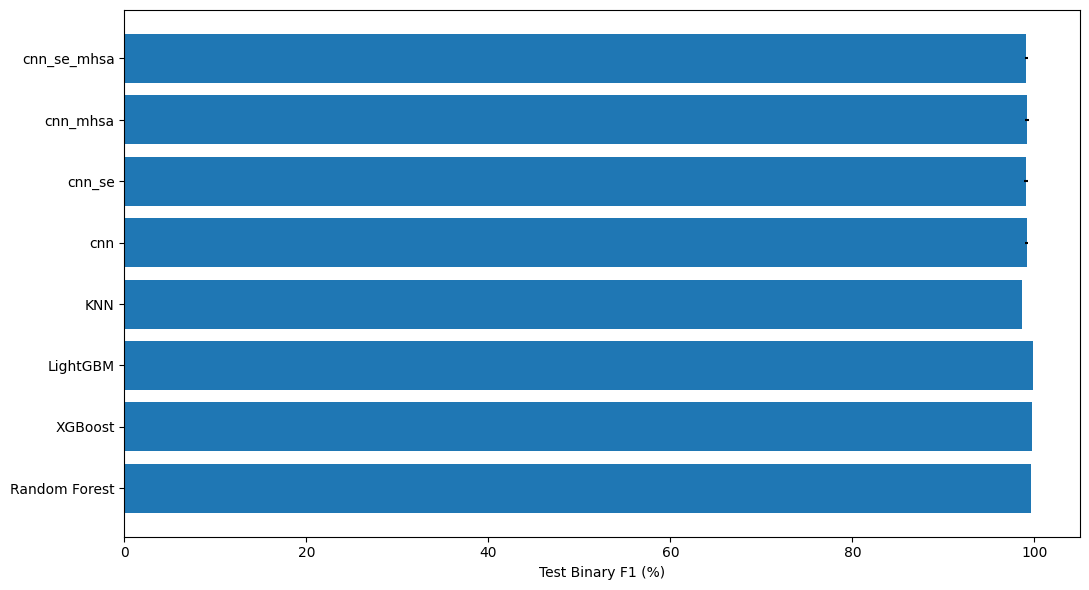

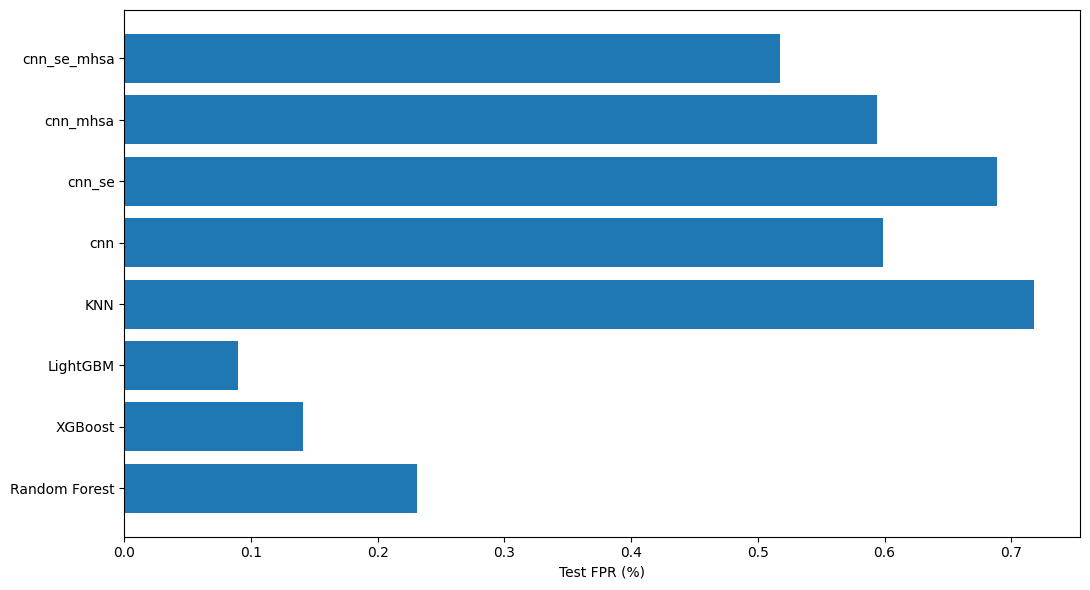

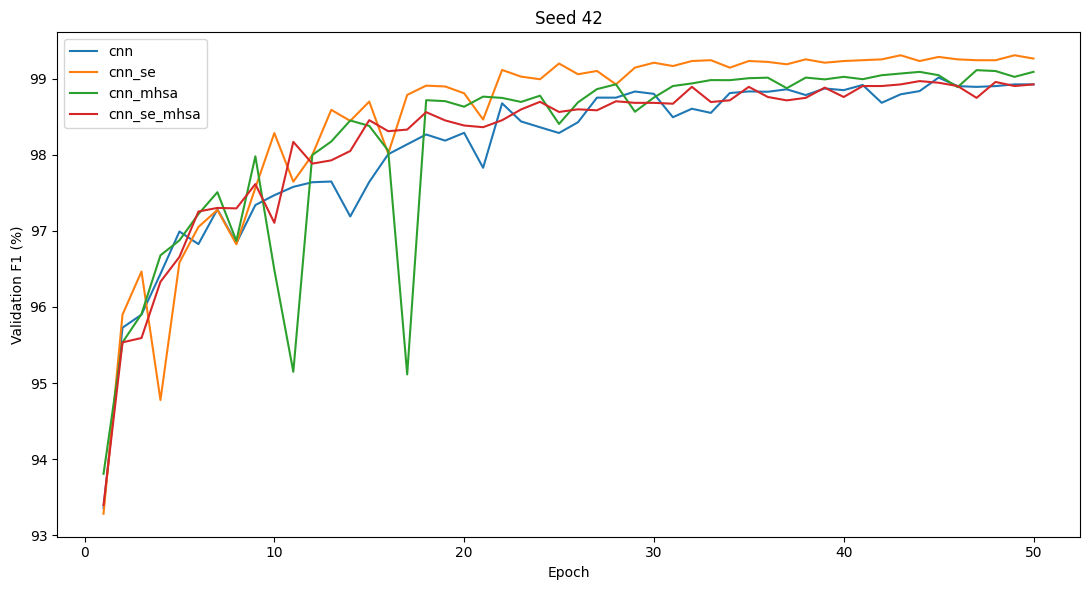

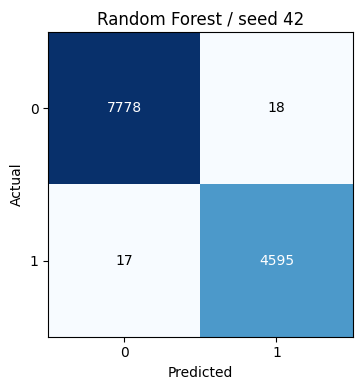

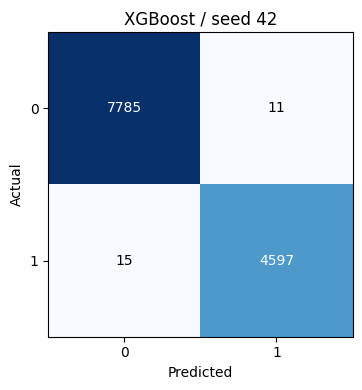

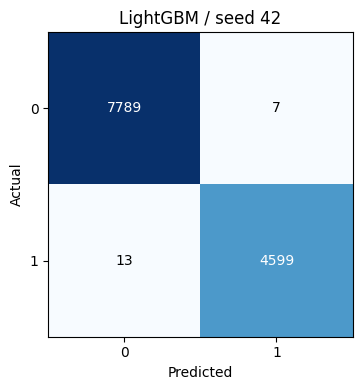

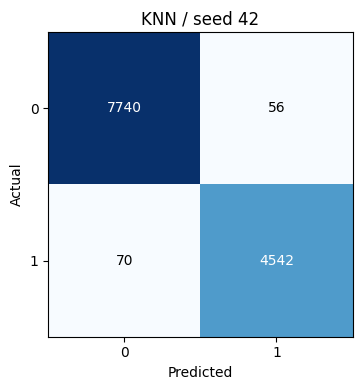

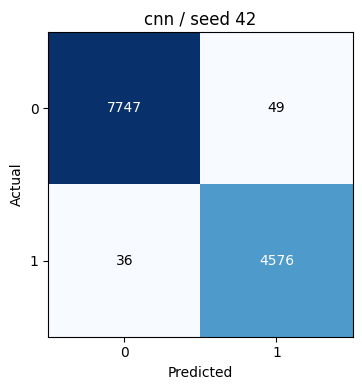

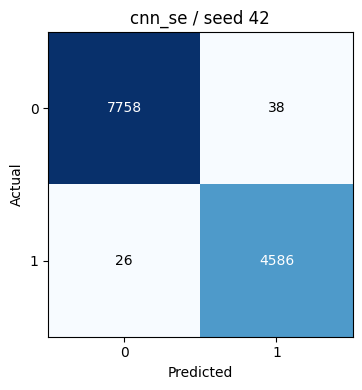

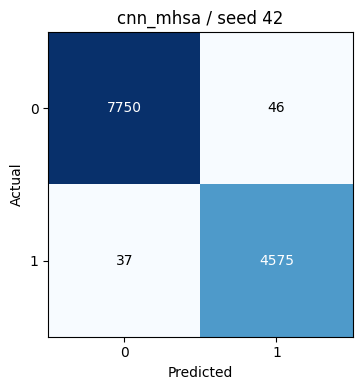

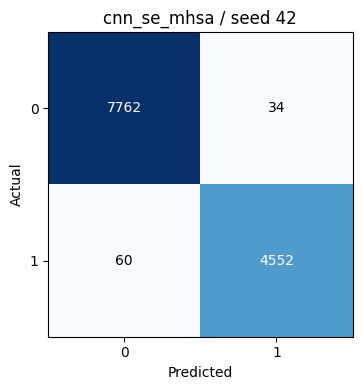

In [26]:
import matplotlib.pyplot as plt
rows=[]; matrices={}
for name,m in baseline['models'].items():
    rows.append(dict(Model=name,Seed=42,Group='ML',TrainingRows=m['training_rows'],ValidationF1=m['validation']['f1_score'],FPR=m['false_positive_rate'],**{k:m['test'][k] for k in ['accuracy','precision','recall','f1_score']}))
    matrices[(name,42)]=m['test']['confusion_matrix']
for seed in SEEDS:
    d=json.loads((RUNS/f'seed_{seed}'/'cnn_metrics.json').read_text()); validate_cnn(d,seed)
    for name,m in d['models'].items():
        rows.append(dict(Model=name,Seed=seed,Group='CNN',TrainingRows=SIZES['train'],ValidationF1=m['validation']['f1_score'],FPR=m['false_positive_rate'],**{k:m['test'][k] for k in ['accuracy','precision','recall','f1_score']}))
        matrices[(name,seed)]=m['test']['confusion_matrix']
raw=pd.DataFrame(rows); raw.to_csv(REPORT/'all_runs.csv',index=False)
cols=['accuracy','precision','recall','f1_score','FPR','ValidationF1']
summary=raw.groupby(['Group','Model'],sort=False)[cols].mean().reset_index()
std=raw.groupby(['Group','Model'],sort=False).f1_score.std().reset_index(name='F1_std')
summary=summary.merge(std,on=['Group','Model']); summary.to_csv(REPORT/'model_summary.csv',index=False)
display(summary)
def save(fig,name):
    fig.tight_layout(); fig.savefig(REPORT/name,dpi=300,bbox_inches='tight'); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(11,6)); ax.barh(summary.Model,summary.f1_score*100,xerr=summary.F1_std.fillna(0)*100); ax.set(xlabel='Test Binary F1 (%)',xlim=(0,105)); save(fig,'01_model_f1.png')
fig,ax=plt.subplots(figsize=(11,6)); ax.barh(summary.Model,summary.FPR*100); ax.set_xlabel('Test FPR (%)'); save(fig,'02_fpr.png')
fig,ax=plt.subplots(figsize=(11,6))
for v in VARIANTS:
    h=pd.read_csv(RUNS/'seed_42'/f'{v}_history.csv'); ax.plot(h.epoch,h.validation_f1*100,label=v)
ax.set(xlabel='Epoch',ylabel='Validation F1 (%)',title='Seed 42'); ax.legend(); save(fig,'03_learning_curves.png')
for (name,seed),mat in matrices.items():
    if seed!=42: continue
    fig,ax=plt.subplots(figsize=(5,4)); ax.imshow(mat,cmap='Blues'); ax.set(xticks=[0,1],yticks=[0,1],xlabel='Predicted',ylabel='Actual',title=f'{name} / seed 42')
    for i in range(2):
        for j in range(2): ax.text(j,i,str(mat[i][j]),ha='center',va='center',color='white' if mat[i][j]>np.max(mat)/2 else 'black')
    save(fig,'cm_'+name.lower().replace(' ','_')+'.png')


## 7. Báo cáo và đóng gói

In [27]:
lines=['# CTU-13 — Full Training và Ablation','','Thiết kế: T01 cố định; CNN seed 42/43/44, baseline seed 42. Train 57.903, validation/test mỗi tập 12.408. KNN giảm mẫu train; xem all_runs.csv.','','| Model | Accuracy | Precision | Recall | Binary F1 | F1 SD | FPR |','|---|---:|---:|---:|---:|---:|---:|']
for _,r in summary.iterrows():
    sd='—' if pd.isna(r.F1_std) else f'{r.F1_std*100:.4f}'
    lines.append(f"| {r.Model} | {r.accuracy*100:.4f}% | {r.precision*100:.4f}% | {r.recall*100:.4f}% | {r.f1_score*100:.4f}% | {sd} | {r.FPR*100:.4f}% |")
lines += ['', 'SD tính theo điểm phần trăm; baseline một seed không có SD.', '', '## Gaussian độc lập', '', f"Validation F1: {g['validation']['f1_score']*100:.4f}%; Test F1: {g['test']['f1_score']*100:.4f}%; Test FPR: {g['test']['false_positive_rate']*100:.4f}%.", '', '## Biểu đồ']
for p in sorted(REPORT.glob('*.png')): lines += ['',f'![{p.stem}]({p.name})']
lines += ['', '## Giới hạn', '', 'Chia tập ngẫu nhiên nội bộ, nhãn CTU theo proxy. Không chọn cấu hình hoặc seed theo test. KNN dùng tập train rút gọn. So sánh baseline một seed với CNN ba seed chỉ mang tính mô tả; chưa khẳng định ý nghĩa thống kê hay hiệu năng realtime.']
(REPORT/'08_CTU_FINAL_TRAINING.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
from zipfile import ZipFile,ZIP_DEFLATED
for name,folder in [('NIDS_CTU13_Final_Results',RUNS),('NIDS_CTU13_Final_Reports',REPORT)]:
    dest=Path('/kaggle/working')/(name+'.zip')
    with ZipFile(dest,'w',ZIP_DEFLATED) as z:
        for p in sorted(folder.rglob('*')):
            if p.is_file(): z.write(p,p.relative_to(ROOT))
    with ZipFile(dest) as z: assert z.testzip() is None
    print(dest)
print('CTU FINAL ARTIFACTS COMPLETED')


/kaggle/working/NIDS_CTU13_Final_Results.zip
/kaggle/working/NIDS_CTU13_Final_Reports.zip
CTU FINAL ARTIFACTS COMPLETED
